# CNN or Vision Transformer for sketch classification

Vision transformers: ViT against a CNN, on accuracy and on cost.

This notebook takes three frozen ImageNet classifiers (ResNet-50, DeiT-Small, DeiT-Base) and measures what they are worth on hand-drawn sketches from 20 ImageNet classes. Nothing is trained. It follows the eight steps of the brief in order and runs top to bottom on a fresh kernel.

In [1]:
# If a library is missing (for example on Colab):  %pip install timm huggingface_hub
import os, platform, random, sys
import numpy as np, torch, torchvision, timm, sklearn, scipy, pandas, matplotlib, PIL, huggingface_hub

SEED = 42                                   # one seed: class choice, dev/test split, bootstrap
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def cpu_name():
    try:
        with open("/proc/cpuinfo") as f:
            return next(l.split(":", 1)[1].strip() for l in f if l.startswith("model name"))
    except Exception:
        return platform.processor() or "unknown CPU"

print("python", sys.version.split()[0], "|", platform.platform())
for lib in (torch, torchvision, timm, np, sklearn, scipy, pandas, matplotlib, PIL, huggingface_hub):
    print(f"{lib.__name__} {lib.__version__}")
print("CPU:", cpu_name(), "|", os.cpu_count(), "threads")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (running on CPU)")
print("seed:", SEED)

/home/tanu/Desktop/Study/M.Tech/CV/assignments/assignment_2/cv2_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python 3.14.9 | Linux-7.3.3-1-cachyos-x86_64-with-glibc2.44
torch 2.15.0+cu132
torchvision 0.29.2+cu132
timm 1.0.31
numpy 2.5.4
sklearn 1.9.1
scipy 1.18.1
pandas 3.1.1
matplotlib 3.11.2
PIL 13.0.0
huggingface_hub 2.4.0
CPU: Intel(R) Core(TM) i5-14400F | 16 threads
GPU: NVIDIA GeForce RTX 5060 Ti
seed: 42


## 1. Problem and track

**Decision supported.** A team wants to classify hand-drawn sketches, for example in a drawing-based search or education app. They have no labelled sketches and no compute to train on, so they must pick an off-the-shelf ImageNet backbone. Should it be a CNN or a vision transformer, once latency and memory are counted next to accuracy?

**Why it is a real question.** Both kinds of model were trained on photographs. A sketch removes colour and texture and keeps shape. ImageNet-trained CNNs are known to lean on texture (Geirhos et al., 2019), and vision transformers have been reported to lean more on shape (Naseer et al., 2021). The hypothesis, stated before looking at results, is that the transformer loses less accuracy on sketches.

**Why Track A.** The decision is a choice between two classifier architectures under a cost budget, which is Track A's claim of accuracy against cost. Track B does not fit because the task is recognising existing images, not generating new ones. Track C does not fit because the labels are a fixed set that ImageNet classifiers already predict; a text encoder would add cost and would mix language pretraining into a CNN-against-transformer comparison.

## 2. Data, licence and contamination

**Source.** ImageNet-Sketch (Wang et al., NeurIPS 2019), downloaded below from the Hugging Face Hub at a pinned commit. Its authors built it from Google Image searches for "sketch of [class name]", restricted to black and white, then cleaned the results by hand. It covers the same 1000 classes as ImageNet-1k, with about 50 images per class.

**Licence.** The dataset repository is released under the MIT licence. The images themselves were scraped from the web and their copyright stays with the original artists; several carry stock-site watermarks. They are used here for evaluation only and are not redistributed: the notebook downloads them.

**Size and choice of classes.** 20 of the 1000 classes, picked by a seeded random sample (not by hand), which gives 1017 images.

**Duplicates and the split.** The dataset authors padded classes that had fewer than 50 images with flipped and rotated copies. The cell after the download finds those copies and splits by drawing, so that no drawing has one copy in dev and another in test. Dev (about 20% of drawings) is used once, in step 8. Everything else is reported on test.

**What the frozen models have probably seen.**
- All three checkpoints were trained on ImageNet-1k photographs only, according to their model cards. ImageNet-Sketch was collected separately in 2019, so these exact images are unlikely to be in the training set. That cannot be verified image by image.
- The classes are not new to the models. All 20 are ImageNet classes, so this measures a change of domain (photo to sketch), not recognition of unseen concepts.
- ImageNet-1k itself contains a small number of drawings and cartoons, so the models have seen some non-photographic images.
- ImageNet-Sketch is a public benchmark, and timm reports results on it. Architectures and training recipes may have been chosen with it in view, which is an indirect form of exposure.
- No checkpoint pretrained on ImageNet-21k or on web-scale image-text data is used, because those may contain sketches.

In [2]:
import zipfile
from pathlib import Path
from huggingface_hub import hf_hub_download

# 1. Download the pinned archive (about 7 GB, cached after the first run)
REPO = "songweig/imagenet_sketch"
REV  = "0d8b8b5380efe50baae075842505918ad43c88fe"   # commit hash = pinned version
zip_path = hf_hub_download(REPO, "data/ImageNet-Sketch.zip",
                           repo_type="dataset", revision=REV)

# 2. Pick 20 classes and extract only those folders
with zipfile.ZipFile(zip_path) as zf:
    jpegs = [n for n in zf.namelist() if n.endswith(".JPEG")]
    all_wnids = sorted({Path(n).parent.name for n in jpegs})   # folder name = class id
    assert len(all_wnids) == 1000
    wnid_to_idx = {w: i for i, w in enumerate(all_wnids)}      # ImageNet-1k index
    chosen = sorted(random.Random(SEED).sample(all_wnids, 20)) # seeded random choice, not hand-picked
    keep = [n for n in jpegs if Path(n).parent.name in chosen]
    zf.extractall("data", members=keep)

# 3. Build the file list (the dev/test split is made in the next cell)
paths  = sorted(str(p) for p in Path("data").rglob("*.JPEG")
                if p.parent.name in chosen)
labels = [wnid_to_idx[Path(p).parent.name] for p in paths]
class_idx = sorted(set(labels))   # the 20 logit positions to keep in step 3

# Readable class names (falls back to folder ids if timm's helper is missing)
try:
    from timm.data import ImageNetInfo
    info = ImageNetInfo()
    class_names = [info.index_to_description(i).split(",")[0] for i in class_idx]
except Exception:
    class_names = chosen

print(len(paths), "images in", len(chosen), "classes")
print(chosen)
print(class_names)

1017 images in 20 classes
['n01629819', 'n01641577', 'n01644900', 'n01819313', 'n01843065', 'n01877812', 'n01945685', 'n02033041', 'n02105505', 'n02110185', 'n02123045', 'n02804610', 'n03372029', 'n03544143', 'n03769881', 'n03871628', 'n04041544', 'n04067472', 'n04069434', 'n04606251']
['European fire salamander', 'bullfrog', 'tailed frog', 'sulphur-crested cockatoo', 'jacamar', 'wallaby', 'slug', 'dowitcher', 'komondor', 'Siberian husky', 'tabby', 'bassoon', 'flute', 'hourglass', 'minibus', 'packet', 'radio', 'reel', 'reflex camera', 'wreck']


1017 images are 574 unique drawings (443 images are copies of another one)
plain random split: 185 of 814 test images would have a copy in dev
split by drawing:   dev 213 images (114 drawings) | test 804 images (460 drawings) | copies across the split: 0

                   class  images  unique drawings  test images  test drawings
European fire salamander      51               20           39             16
                bullfrog      50               25           40             20
             tailed frog      51               30           41             23
sulphur-crested cockatoo      51               48           41             39
                 jacamar      51               18           40             14
                 wallaby      51               44           40             35
                    slug      51               15           41             12
               dowitcher      50               10           40              8
                komondor      51          

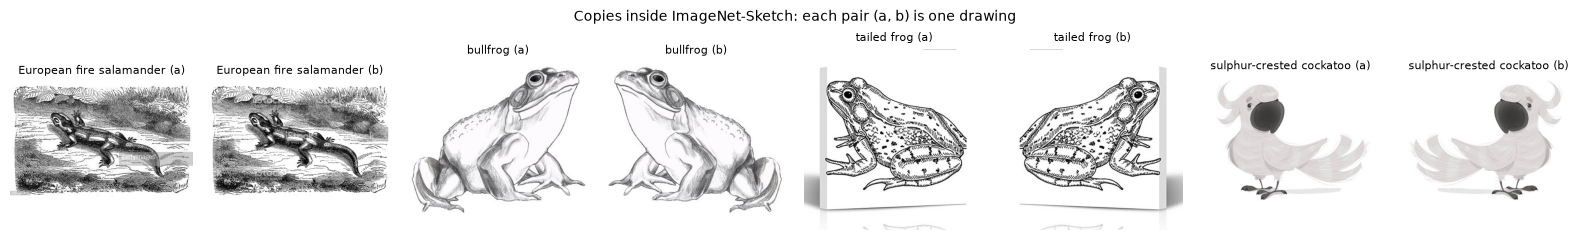

In [3]:
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import train_test_split

# ImageNet-Sketch pads small classes with flipped and rotated copies of the same drawing.
# A plain random split would put copies on both sides, so: group the copies first, then split groups.
S = 64
thumbs = np.stack([np.asarray(Image.open(p).convert("L").resize((S, S), Image.BILINEAR),
                              dtype=np.float32) for p in paths])

def unit(v):                                   # centre and L2-normalise each thumbnail
    v = v.reshape(len(v), -1)
    v = v - v.mean(axis=1, keepdims=True)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)

base = unit(thumbs)
sim = np.full((len(paths), len(paths)), -1.0, dtype=np.float32)
for k in range(4):                             # 4 rotations x mirror = 8 orientations
    rot = np.rot90(thumbs, k, axes=(1, 2))
    for v in (rot, rot[:, :, ::-1]):
        sim = np.maximum(sim, base @ unit(np.ascontiguousarray(v)).T)
np.fill_diagonal(sim, -1)

# Pixel correlation of 64x64 thumbnails. Exact copies score about 1.0. The threshold was set by
# looking at image pairs; no model output is involved. It leans towards grouping too much,
# because a missed copy is a leak and an extra grouping costs nothing.
DUP_THRESHOLD = 0.95
n_groups, group = connected_components(sim >= DUP_THRESHOLD, directed=False)

# What a plain random 20/80 split would have leaked
naive_dev, naive_test = train_test_split(np.arange(len(paths)), test_size=0.8,
                                         stratify=labels, random_state=SEED)
leaked = np.isin(group[naive_test], group[naive_dev]).sum()

# The split actually used: by drawing (group), stratified by class, 20% dev / 80% test
first = np.array([np.flatnonzero(group == g)[0] for g in range(n_groups)])
dev_g, test_g = train_test_split(np.arange(n_groups), test_size=0.8,
                                 stratify=[labels[i] for i in first], random_state=SEED)
is_dev = np.isin(group, dev_g)
dev_p  = [p for p, d in zip(paths, is_dev) if d]
dev_y  = [y for y, d in zip(labels, is_dev) if d]
test_p = [p for p, d in zip(paths, is_dev) if not d]
test_y = [y for y, d in zip(labels, is_dev) if not d]
test_group = group[~is_dev]                    # drawing id of each test image, used by the bootstrap
assert not set(group[is_dev]) & set(test_group)   # no drawing on both sides

print(f"{len(paths)} images are {n_groups} unique drawings "
      f"({len(paths) - n_groups} images are copies of another one)")
print(f"plain random split: {leaked} of {len(naive_test)} test images would have a copy in dev")
print(f"split by drawing:   dev {len(dev_p)} images ({len(dev_g)} drawings) | "
      f"test {len(test_p)} images ({len(test_g)} drawings) | copies across the split: 0")

lab = np.array(labels)
per_class = pd.DataFrame({
    "class": class_names,
    "images": [(lab == c).sum() for c in class_idx],
    "unique drawings": [len(set(group[lab == c])) for c in class_idx],
    "test images": [((lab == c) & ~is_dev).sum() for c in class_idx],
    "test drawings": [len(set(group[(lab == c) & ~is_dev])) for c in class_idx]})
print(); print(per_class.to_string(index=False))

# Label noise: the same drawing filed under more than one class
name_of = dict(zip(class_idx, class_names))
mixed = [g for g in range(n_groups) if len(set(lab[group == g])) > 1]
print(f"\ndrawings that appear under more than one class label: {len(mixed)}")
for g in mixed:
    print("  ", ", ".join(f"{name_of[c]} x{(lab[group == g] == c).sum()}" for c in sorted(set(lab[group == g]))))

# Evidence: the first drawing that has a copy, in each of the first four classes
shown = [next(g for g in sorted(set(group[lab == c])) if (group == g).sum() > 1 and g not in mixed)
         for c in class_idx[:4]]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for k, g in enumerate(shown):
    for q, i in enumerate(np.flatnonzero(group == g)[:2]):
        ax = axes[2 * k + q]
        ax.imshow(Image.open(paths[i]).convert("RGB")); ax.axis("off")
        ax.set_title(f"{class_names[class_idx.index(labels[i])]} ({'ab'[q]})", fontsize=8)
plt.suptitle("Copies inside ImageNet-Sketch: each pair (a, b) is one drawing", fontsize=10)
plt.tight_layout(); plt.savefig("duplicate_examples.png", dpi=150); plt.show()

## 3. The frozen baseline

Three checkpoints from timm, each pinned to a commit hash on the Hugging Face Hub:

| Role | Checkpoint | Training data |
|---|---|---|
| CNN baseline | `resnet50.a1_in1k` | ImageNet-1k |
| ViT baseline | `deit_small_patch16_224.fb_in1k` | ImageNet-1k |
| ViT after the intervention | `deit_base_patch16_224.fb_in1k` | ImageNet-1k |

ResNet-50 and DeiT-Small have a similar number of parameters. The ResNet uses the "ResNet strikes back" A1 weights, whose training recipe is close to DeiT's, so that the comparison is less a comparison of training recipes.

**What is not changed.** The weights are frozen and run in evaluation mode. Each model uses the preprocessing stored in its own checkpoint (resize, centre crop, bicubic interpolation, ImageNet mean and standard deviation). All three run at 224 x 224. The ResNet model card also lists a 288-pixel test setting; it is not used, so that input size, and with it cost, is the same for all three.

**The one thing added on top.** The models output 1000 ImageNet scores. The app only has 20 classes, so the 20 matching scores are kept and the softmax is taken over those. The unrestricted 1000-way accuracy is reported next to it.

In [4]:
import timm, torch
from timm.data import resolve_model_data_config, create_transform

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# repo id @ commit hash = exact pinned checkpoint
CHECKPOINTS = {
    "resnet50":   "timm/resnet50.a1_in1k@767268603ca0cb0bfe326fa87277f19c419566ef",
    "deit_small": "timm/deit_small_patch16_224.fb_in1k@91327a9c99f98fe6b524cd4d397b7226b80e1365",
    "deit_base":  "timm/deit_base_patch16_224.fb_in1k@b78cc5532a69df6bcad9c3a8d76653fd20b31ac6",
}

def load_frozen(hub_id):
    model = timm.create_model("hf_hub:" + hub_id, pretrained=True)
    model = model.eval().to(DEVICE)              # eval: no dropout, fixed batch-norm stats
    for p in model.parameters():
        p.requires_grad_(False)                  # frozen: no gradients, no updates
    cfg = resolve_model_data_config(model)       # the preprocessing this checkpoint expects
    transform = create_transform(**cfg, is_training=False)
    return model, transform, cfg

models = {}
for name, hub_id in CHECKPOINTS.items():
    model, transform, cfg = load_frozen(hub_id)
    models[name] = (model, transform)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"{name}: {n_params:.1f}M params | input {cfg['input_size']} | "
          f"crop {cfg['crop_pct']} | {cfg['interpolation']} | mean {cfg['mean']}")

resnet50: 25.6M params | input [3, 224, 224] | crop 0.95 | bicubic | mean [0.485, 0.456, 0.406]
deit_small: 22.1M params | input [3, 224, 224] | crop 0.9 | bicubic | mean [0.485, 0.456, 0.406]


deit_base: 86.6M params | input [3, 224, 224] | crop 0.9 | bicubic | mean [0.485, 0.456, 0.406]


In [5]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class SketchSet(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # sketches may be 1-channel
        return self.transform(img), self.labels[i]

idx_t = torch.tensor(class_idx, device=DEVICE)        # the 20 ImageNet indices we kept
pos   = {c: i for i, c in enumerate(class_idx)}       # ImageNet index -> 0..19

@torch.no_grad()
def run_model(name, paths, labels):
    model, transform = models[name]
    loader = DataLoader(SketchSet(paths, labels, transform),
                        batch_size=64, shuffle=False, num_workers=0)
    probs, hit1000 = [], []
    for x, y1000 in loader:
        full = model(x.to(DEVICE))                        # all 1000 ImageNet scores
        hit1000.append(full.argmax(dim=1).cpu() == y1000) # unrestricted 1000-way answer right?
        probs.append(full[:, idx_t].softmax(dim=1).cpu()) # softmax over our 20 only
    probs = torch.cat(probs)
    conf, pred = probs.max(dim=1)                     # top score and its class
    y = torch.tensor([pos[l] for l in labels])
    return {"probs": probs.numpy(), "pred": pred.numpy(),
            "conf": conf.numpy(), "y": y.numpy(),
            "hit1000": torch.cat(hit1000).numpy()}

# dev is kept for one job only: choosing the abstain threshold in step 8.
# Nothing is tuned on test.
dev_results, results = {}, {}
for name in ["resnet50", "deit_small"]:
    dev_results[name] = run_model(name, dev_p, dev_y)
    d = dev_results[name]
    print(f"[dev]  {name}: acc {(d['pred'] == d['y']).mean():.3f}")

for name in ["resnet50", "deit_small"]:
    results[name] = run_model(name, test_p, test_y)
    r = results[name]
    print(f"[test] {name}: 20-way acc {(r['pred'] == r['y']).mean():.3f} | "
          f"1000-way acc {r['hit1000'].mean():.3f} | "
          f"mean confidence {r['conf'].mean():.3f}")

[dev]  resnet50: acc 0.657


[dev]  deit_small: acc 0.700


[test] resnet50: 20-way acc 0.655 | 1000-way acc 0.276 | mean confidence 0.707


[test] deit_small: 20-way acc 0.684 | 1000-way acc 0.282 | mean confidence 0.694


In [6]:
def correct(name):
    r = results[name]
    return r["pred"] == r["y"]                 # True/False per test image

# Copies of one drawing are not independent samples, so the bootstrap resamples whole
# drawings, not single images. The same 2000 resamples are reused for every interval below.
members = [np.flatnonzero(test_group == g) for g in np.unique(test_group)]
rng = np.random.default_rng(SEED)
BOOT = [np.concatenate([members[j] for j in rng.integers(0, len(members), len(members))])
        for _ in range(2000)]

def ci(stat):                                  # 95% interval of stat(test indices)
    return np.percentile([stat(i) for i in BOOT], [2.5, 97.5])

def compare(a_name, b_name):
    a, b = correct(a_name), correct(b_name)
    lo, hi = ci(lambda i: b[i].mean() - a[i].mean())
    print(f"{b_name} minus {a_name}: {b.mean() - a.mean():+.3f} "
          f"(95% CI {lo:+.3f} to {hi:+.3f})")
    print(f"   images only {a_name} gets right: {(a & ~b).sum()} | "
          f"only {b_name}: {(b & ~a).sum()} | "
          f"{len(a)} test images, {len(members)} unique drawings")

# The Track A question: CNN against ViT at a similar parameter count
compare("resnet50", "deit_small")

deit_small minus resnet50: +0.029 (95% CI -0.010 to +0.067)
   images only resnet50 gets right: 62 | only deit_small: 85 | 804 test images, 460 unique drawings


## 4. One controlled intervention: backbone size

DeiT-Small is replaced by DeiT-Base. Both come from the same family, the same training recipe and the same training data, and they go through the same code path here: same test images in the same order, same preprocessing, same 20-class restriction, same seed. The only thing that changes is the size of the backbone (22M to 87M parameters).

In [7]:
import pandas as pd

# The intervention: one change (backbone size), everything else identical
results["deit_base"] = run_model("deit_base", test_p, test_y)

# Published ImageNet-1k top-1 at 224 px (timm results-imagenet.csv). Context only:
# those are photographs over all 1000 classes, not our 20-class sketch subset.
PUBLISHED_IN1K = {"resnet50": 80.38, "deit_small": 79.86, "deit_base": 81.98}

rows, acc_ci = [], {}
for name, role in [("resnet50",   "CNN baseline"),
                   ("deit_small", "ViT baseline (before)"),
                   ("deit_base",  "ViT intervention (after)")]:
    c = correct(name)
    acc_ci[name] = ci(lambda i: c[i].mean())          # reused for the error bars in step 5
    rows.append({"model": name, "role": role,
                 "acc 20-way": c.mean(),
                 "95% CI": f"{acc_ci[name][0]:.3f}-{acc_ci[name][1]:.3f}",
                 "acc 1000-way": results[name]["hit1000"].mean(),
                 "ImageNet top-1 (published)": PUBLISHED_IN1K[name] / 100,
                 "mean confidence": results[name]["conf"].mean()})
summary = pd.DataFrame(rows)
print(summary.round(3).to_string(index=False))

# Is the before/after gap real, or noise from a small test set?
print()
compare("deit_small", "deit_base")

     model                     role  acc 20-way      95% CI  acc 1000-way  ImageNet top-1 (published)  mean confidence
  resnet50             CNN baseline       0.655 0.611-0.698         0.276                       0.804            0.707
deit_small    ViT baseline (before)       0.684 0.640-0.725         0.282                       0.799            0.694
 deit_base ViT intervention (after)       0.664 0.621-0.706         0.297                       0.820            0.672

deit_base minus deit_small: -0.020 (95% CI -0.054 to +0.015)
   images only deit_small gets right: 77 | only deit_base: 61 | 804 test images, 460 unique drawings


## 5. Evaluation: accuracy and cost

Accuracy first: per-class precision, recall and F1, and a confusion matrix for each model, all on the test split. Then cost, timed on this machine: parameters, milliseconds per image and peak memory.


===== resnet50 =====
                          precision    recall  f1-score   support

European fire salamander      0.917     0.846     0.880        39
                bullfrog      0.526     0.250     0.339        40
             tailed frog      0.569     0.707     0.630        41
sulphur-crested cockatoo      0.938     0.366     0.526        41
                 jacamar      0.917     0.550     0.688        40
                 wallaby      1.000     0.550     0.710        40
                    slug      0.793     0.561     0.657        41
               dowitcher      0.737     0.700     0.718        40
                komondor      0.871     0.711     0.783        38
          Siberian husky      0.947     0.878     0.911        41
                   tabby      0.830     0.975     0.897        40
                 bassoon      0.516     0.821     0.634        39
                   flute      0.567     0.459     0.507        37
               hourglass      0.367     1.000     0.5

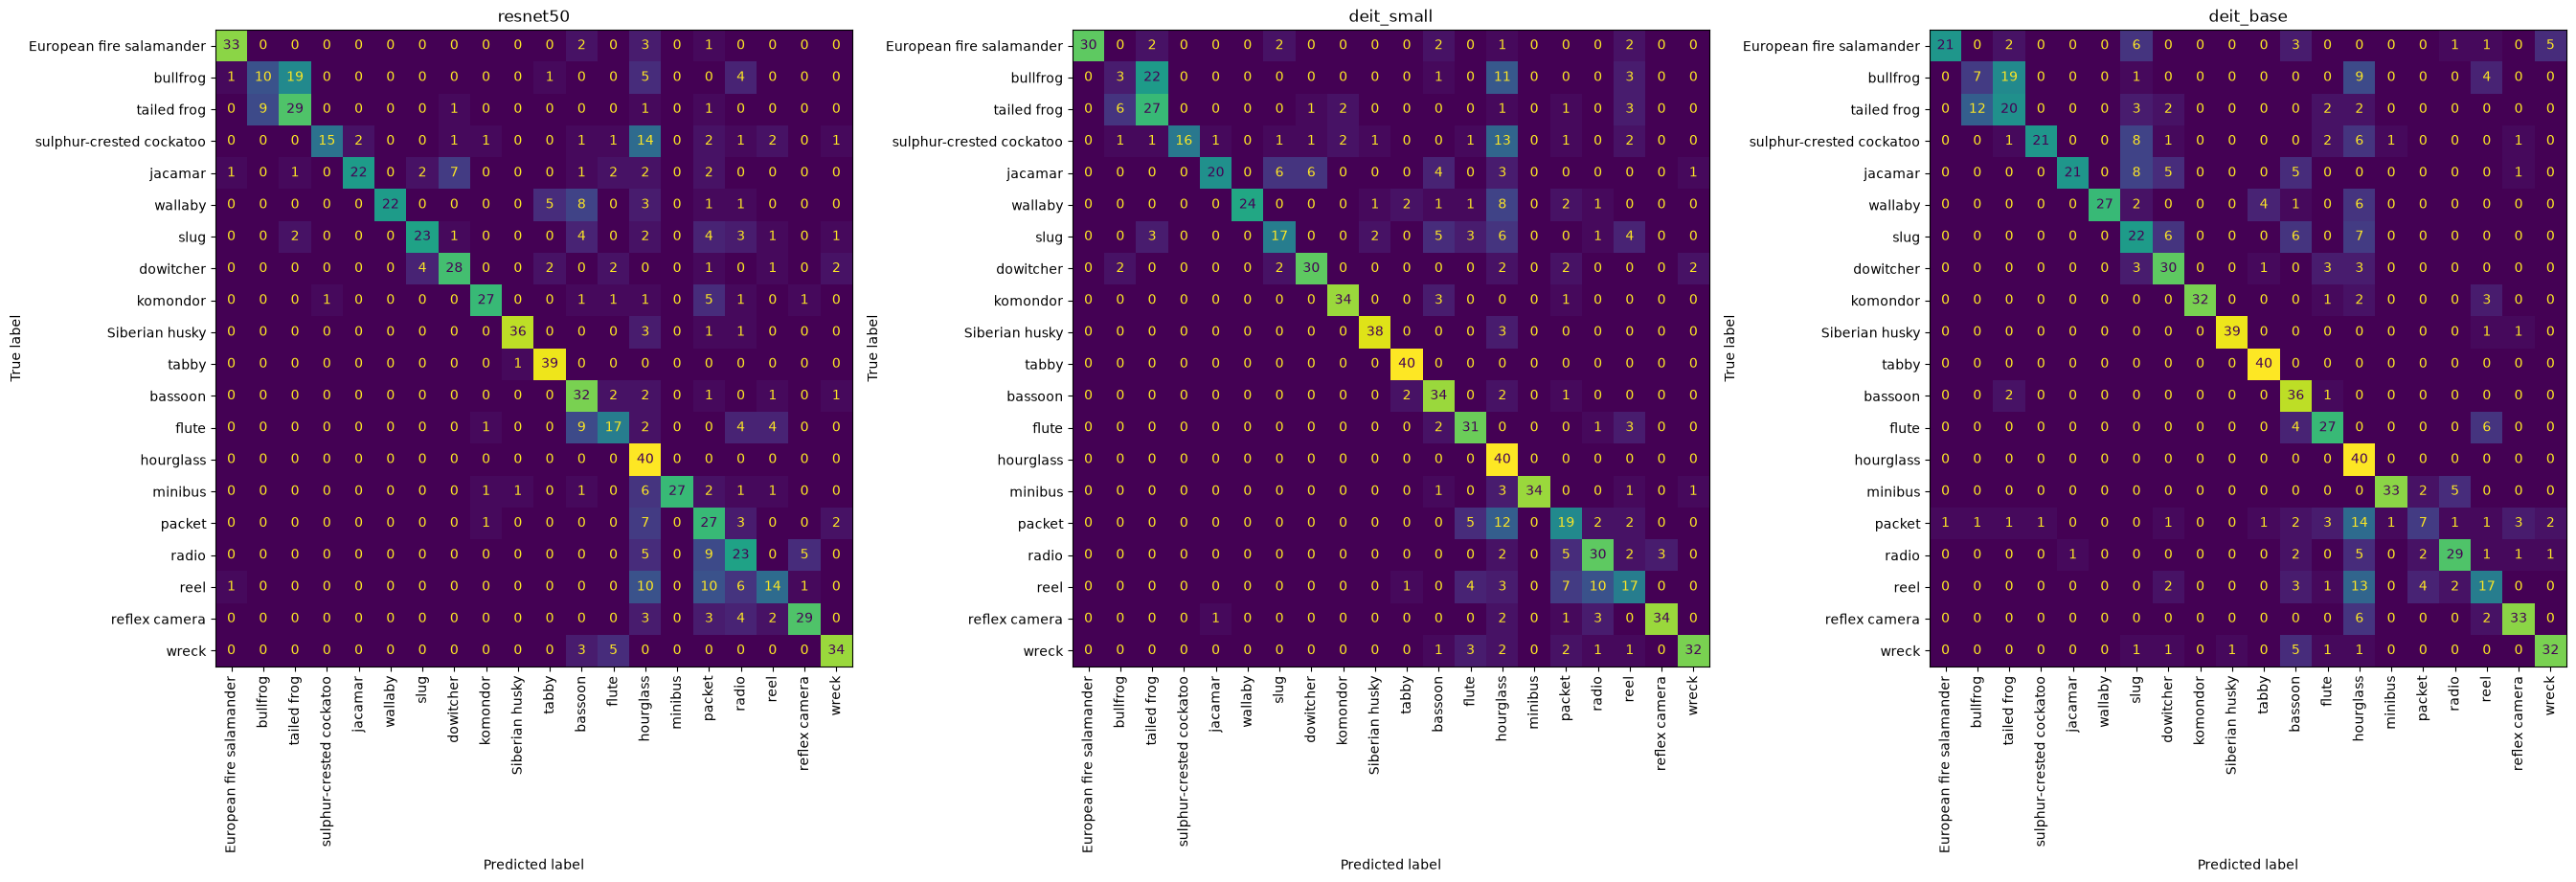

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

MODELS = ["resnet50", "deit_small", "deit_base"]

# ---------- Accuracy: per-class precision, recall, F1 and confusion matrices ----------
for name in MODELS:
    r = results[name]
    print(f"\n===== {name} =====")
    print(classification_report(r["y"], r["pred"], target_names=class_names,
                                digits=3, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(27, 9))
for ax, name in zip(axes, MODELS):
    r = results[name]
    ConfusionMatrixDisplay.from_predictions(r["y"], r["pred"], display_labels=class_names,
                                            ax=ax, xticks_rotation=90, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

GPU: NVIDIA GeForce RTX 5060 Ti | CPU: Intel(R) Core(TM) i5-14400F (10 threads used by PyTorch)
     model  params (M)  weights MB  CPU ms/img   CPU 5-95%  GPU ms/img b=1 GPU 5-95%  peak GPU MB b=1  GPU ms/img b=32  peak GPU MB b=32
  resnet50       25.56       97.70       31.71   31.4-32.9            3.18 3.04-3.46           115.01             1.37            435.41
deit_small       22.05       84.12       35.92   35.6-36.3            3.13 2.94-3.37            89.03             1.14            214.35
 deit_base       86.57      330.23      114.81 113.9-115.5            6.44 6.28-6.69           339.48             3.78            572.80


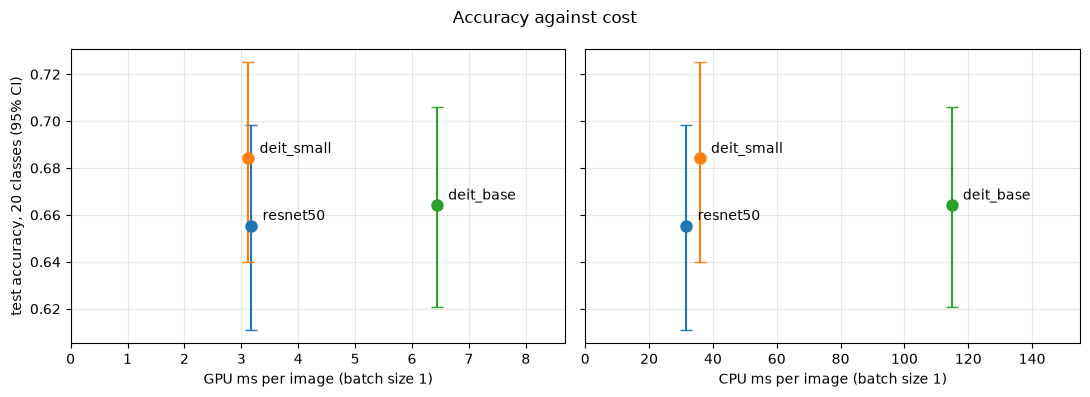

In [9]:
import time

# ---------- Cost: parameters, latency and peak memory, timed on this machine ----------
@torch.no_grad()
def time_forward(model, x, n_warm, n_rep):
    """Milliseconds per image over repeated forward passes: median, 5th and 95th percentile."""
    sync = torch.cuda.synchronize if x.is_cuda else (lambda: None)
    for _ in range(n_warm):                      # warm-up runs, not timed
        model(x)
    sync()
    t = []
    for _ in range(n_rep):
        t0 = time.perf_counter(); model(x); sync()
        t.append((time.perf_counter() - t0) * 1000 / len(x))
    return np.percentile(t, [50, 5, 95])

@torch.no_grad()
def peak_gpu_mb(model, x):                       # weights + activations of one forward pass
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model(x); torch.cuda.synchronize()
    return torch.cuda.max_memory_allocated() / 2**20

def measure_cost(name):
    model, transform = models[name]
    x1 = transform(Image.open(test_p[0]).convert("RGB")).unsqueeze(0)   # one preprocessed image
    tensors = list(model.parameters()) + list(model.buffers())
    row = {"model": name,
           "params (M)": sum(p.numel() for p in model.parameters()) / 1e6,
           "weights MB": sum(t.numel() * t.element_size() for t in tensors) / 2**20}

    for m, _ in models.values():                 # only the timed model may sit on the GPU
        m.to("cpu")
    med, lo, hi = time_forward(model, x1, n_warm=5, n_rep=30)
    row["CPU ms/img"] = med; row["CPU 5-95%"] = f"{lo:.1f}-{hi:.1f}"

    if DEVICE == "cuda":
        model.to(DEVICE); g1 = x1.to(DEVICE)
        med, lo, hi = time_forward(model, g1, n_warm=20, n_rep=200)
        row["GPU ms/img b=1"] = med; row["GPU 5-95%"] = f"{lo:.2f}-{hi:.2f}"
        row["peak GPU MB b=1"] = peak_gpu_mb(model, g1)
        g32 = g1.repeat(32, 1, 1, 1)             # throughput setting: 32 images at once
        row["GPU ms/img b=32"] = time_forward(model, g32, n_warm=5, n_rep=30)[0]
        row["peak GPU MB b=32"] = peak_gpu_mb(model, g32)
        del g1, g32; model.to("cpu")
    return row

cost = pd.DataFrame([measure_cost(n) for n in MODELS])
for m, _ in models.values():                     # put all models back
    m.to(DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none",
      "| CPU:", cpu_name(), f"({torch.get_num_threads()} threads used by PyTorch)")
print(cost.round(2).to_string(index=False))

# The headline figure: accuracy against cost, with the uncertainty of the accuracy shown
panels = [c for c in ["GPU ms/img b=1", "CPU ms/img"] if c in cost]
fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4), sharey=True, squeeze=False)
for ax, col in zip(axes[0], panels):
    for _, row in cost.iterrows():
        name = row["model"]; acc = correct(name).mean(); lo, hi = acc_ci[name]
        ax.errorbar(row[col], acc, yerr=[[acc - lo], [hi - acc]], fmt="o", capsize=4, markersize=8)
        ax.annotate(name, (row[col], acc), textcoords="offset points", xytext=(8, 4))
    ax.set_xlim(0, cost[col].max() * 1.35)
    ax.set_xlabel(col.replace("ms/img", "ms per image").replace("b=1", "(batch size 1)")
                  + ("" if "GPU" in col else " (batch size 1)"))
    ax.grid(alpha=0.3)
axes[0][0].set_ylabel("test accuracy, 20 classes (95% CI)")
fig.suptitle("Accuracy against cost")
plt.tight_layout(); plt.savefig("accuracy_vs_cost.png", dpi=150); plt.show()

## 6. Confidence against correctness

The confidence used here is the largest softmax value over the 20 kept classes. It is a score, not a probability. Two checks follow. The reliability diagram asks whether a confidence of, say, 0.8 goes with being right about 80% of the time. The coverage curve asks whether the model's most confident answers are in fact its most accurate ones.

resnet50: accuracy 0.655 | mean confidence 0.707 | ECE 0.063 | confidence when wrong 0.465
deit_small: accuracy 0.684 | mean confidence 0.694 | ECE 0.053 | confidence when wrong 0.435
deit_base: accuracy 0.664 | mean confidence 0.672 | ECE 0.019 | confidence when wrong 0.389


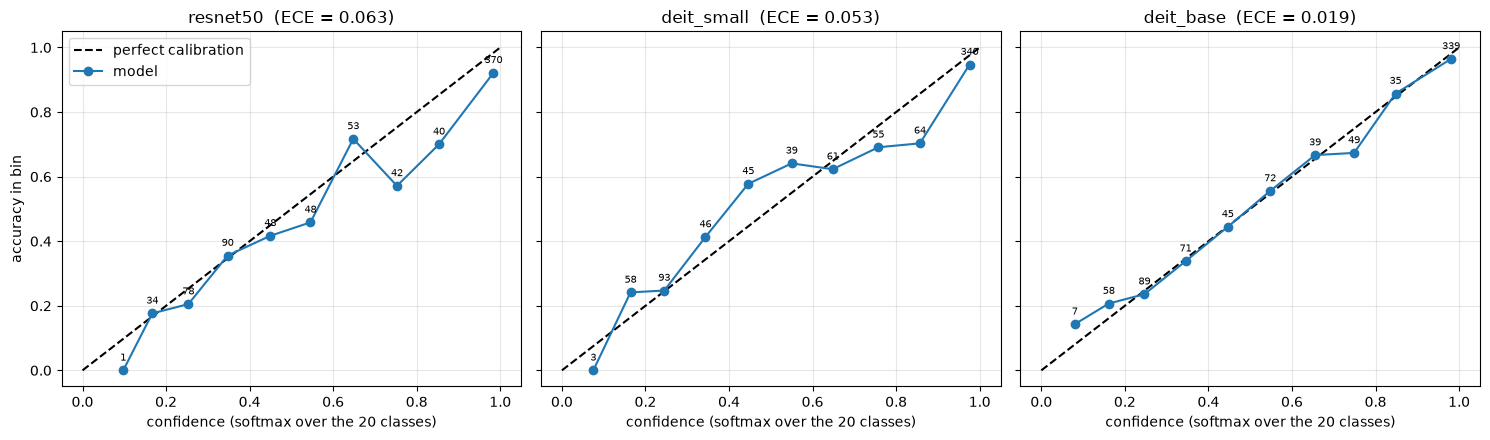

In [10]:
def calibration(name, n_bins=10):
    r = results[name]
    conf = r["conf"]                             # top softmax score per image
    ok   = r["pred"] == r["y"]                   # prediction vs ground truth
    edges = np.linspace(0, 1, n_bins + 1)
    which = np.digitize(conf, edges[1:-1])       # bin number 0..9 for each image
    rows, ece = [], 0.0
    for k in range(n_bins):
        m = which == k
        if m.sum() == 0:
            continue
        acc_k, conf_k = ok[m].mean(), conf[m].mean()
        ece += m.mean() * abs(acc_k - conf_k)    # gap, weighted by bin size
        rows.append((conf_k, acc_k, m.sum()))
    return np.array(rows), ece

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, MODELS):
    rows, ece = calibration(name)
    r = results[name]
    ok = correct(name)
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax.plot(rows[:, 0], rows[:, 1], "o-", label="model")
    for conf_k, acc_k, n_k in rows:
        ax.annotate(int(n_k), (conf_k, acc_k), textcoords="offset points", xytext=(0, 7),
                    ha="center", fontsize=7)     # images in that bin
    ax.set_title(f"{name}  (ECE = {ece:.3f})")
    ax.set_xlabel("confidence (softmax over the 20 classes)"); ax.grid(alpha=0.3)
    print(f"{name}: accuracy {ok.mean():.3f} | mean confidence {r['conf'].mean():.3f} | "
          f"ECE {ece:.3f} | confidence when wrong {r['conf'][~ok].mean():.3f}")
axes[0].set_ylabel("accuracy in bin"); axes[0].legend()
plt.tight_layout(); plt.savefig("reliability.png", dpi=150); plt.show()

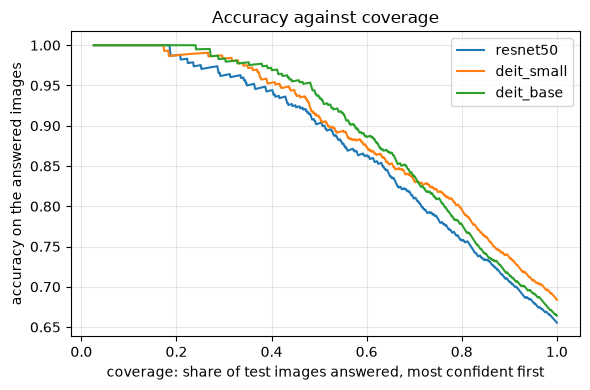

     model AUROC, confidence vs right/wrong (95% CI) mean confidence minus accuracy (95% CI)  acc @ 100%  acc @ 75%  acc @ 50%  acc @ 25%
  resnet50                    0.854 (0.819 to 0.889)               +0.052 (+0.017 to +0.088)       0.655      0.784      0.903      0.975
deit_small                    0.855 (0.820 to 0.889)               +0.009 (-0.025 to +0.045)       0.684      0.818      0.910      0.990
 deit_base                    0.883 (0.853 to 0.911)               +0.008 (-0.023 to +0.038)       0.664      0.809      0.935      0.995


In [11]:
from sklearn.metrics import roc_auc_score

# Does confidence rank right answers above wrong ones?
# Answer only the most confident share of images and see what accuracy that leaves.
rows = []
plt.figure(figsize=(6, 4))
for name in MODELS:
    conf, ok = results[name]["conf"], correct(name)
    order = np.argsort(-conf)                    # most confident first
    kept_acc = np.cumsum(ok[order]) / np.arange(1, len(ok) + 1)
    coverage = np.arange(1, len(ok) + 1) / len(ok)
    plt.plot(coverage[20:], kept_acc[20:], label=name)   # first 20 points are too noisy to draw
    a_lo, a_hi = ci(lambda i: roc_auc_score(ok[i], conf[i]))
    g_lo, g_hi = ci(lambda i: conf[i].mean() - ok[i].mean())
    row = {"model": name,
           "AUROC, confidence vs right/wrong (95% CI)":
               f"{roc_auc_score(ok, conf):.3f} ({a_lo:.3f} to {a_hi:.3f})",
           "mean confidence minus accuracy (95% CI)":
               f"{conf.mean() - ok.mean():+.3f} ({g_lo:+.3f} to {g_hi:+.3f})"}
    for share in (1.0, 0.75, 0.5, 0.25):
        row[f"acc @ {share:.0%}"] = kept_acc[int(round(share * len(ok))) - 1]
    rows.append(row)
plt.xlabel("coverage: share of test images answered, most confident first")
plt.ylabel("accuracy on the answered images")
plt.title("Accuracy against coverage"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("coverage.png", dpi=150); plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))

## 7. Attention map and failure analysis

**Attention map.** The class token's attention over the image patches in DeiT-Small's last layer, averaged over heads, for the first correctly classified test image. This is one view of one layer. It shows where the class token reads from at that layer, not why the model chose its answer.

**Failures.** The eight most confident mistakes of DeiT-Small, chosen by that rule and not by hand, showing each drawing once. Below the grid, the most frequent confusions for every model.

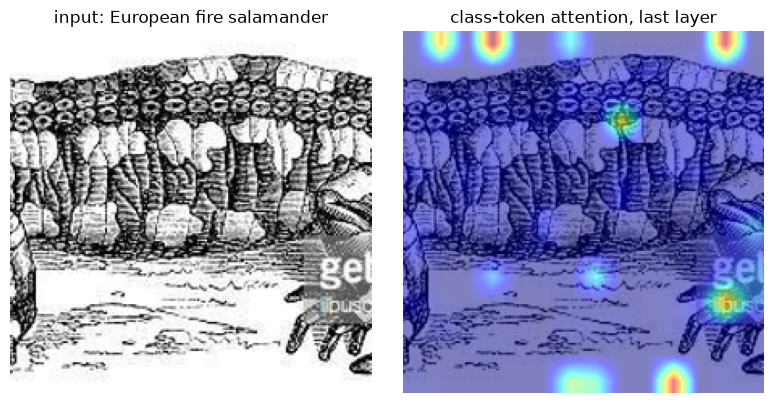

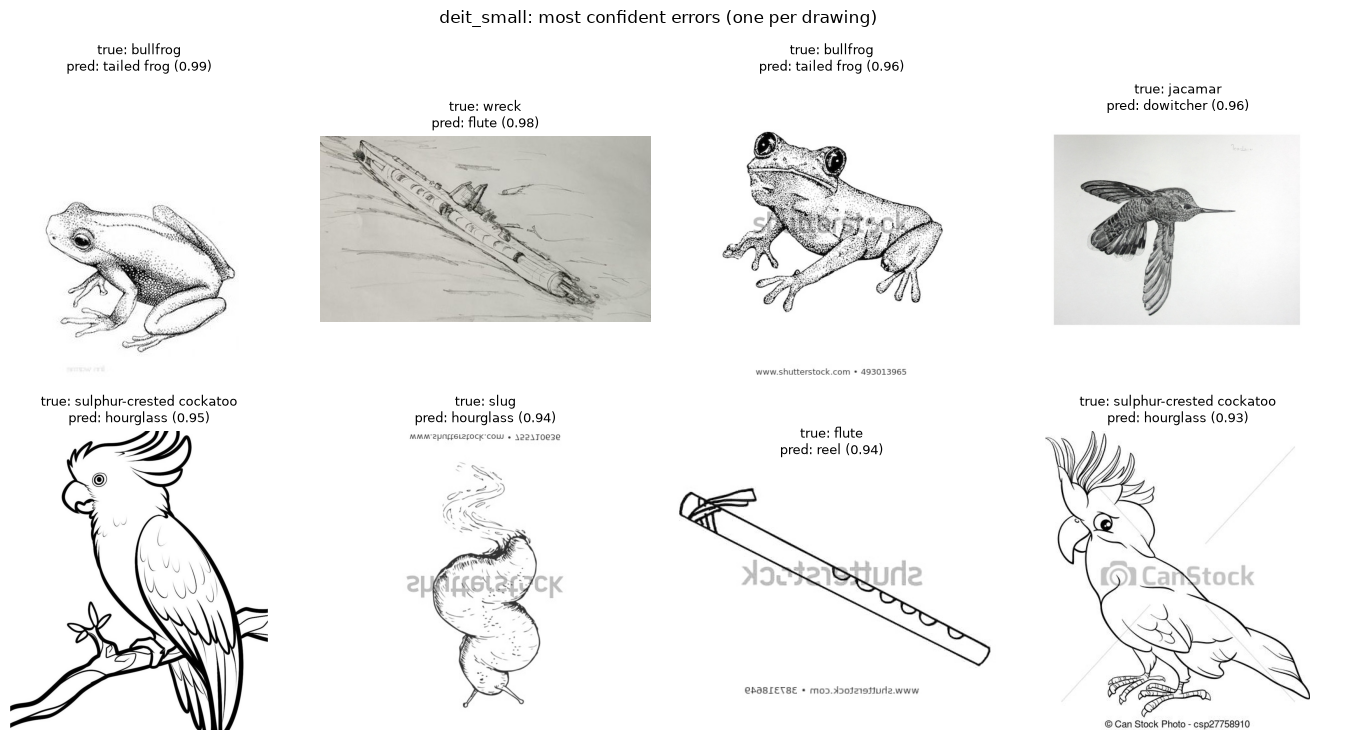


resnet50: 277 errors on 171 unique drawings. Most common (true -> predicted):
   bullfrog -> tailed frog: 19
   sulphur-crested cockatoo -> hourglass: 14
   reel -> hourglass: 10
   reel -> packet: 10
   tailed frog -> bullfrog: 9
   most over-predicted class: 'hourglass' absorbs 69 of 277 errors (25%)

deit_small: 254 errors on 155 unique drawings. Most common (true -> predicted):
   bullfrog -> tailed frog: 22
   sulphur-crested cockatoo -> hourglass: 13
   packet -> hourglass: 12
   bullfrog -> hourglass: 11
   reel -> radio: 10
   most over-predicted class: 'hourglass' absorbs 74 of 254 errors (29%)

deit_base: 270 errors on 158 unique drawings. Most common (true -> predicted):
   bullfrog -> tailed frog: 19
   packet -> hourglass: 14
   reel -> hourglass: 13
   tailed frog -> bullfrog: 12
   bullfrog -> hourglass: 9
   most over-predicted class: 'hourglass' absorbs 74 of 270 errors (27%)

Images all three models get wrong: 155 of 804 (100 unique drawings)


In [12]:
import torch.nn.functional as F
from collections import Counter

# ---------- Part A: one attention map (DeiT-Small, last layer) ----------
@torch.no_grad()
def cls_attention(name, path):
    model, transform = models[name]
    x = transform(Image.open(path).convert("RGB")).unsqueeze(0).to(DEVICE)
    blk, grabbed = model.blocks[-1], {}
    hook = blk.attn.register_forward_hook(lambda m, inp, out: grabbed.update(x=inp[0]))
    model(x); hook.remove()                      # capture the input to the last attention layer

    t = grabbed["x"]                             # (1, 197, C): 1 class token + 196 patches
    B, N, C = t.shape
    heads = blk.attn.num_heads
    qkv = blk.attn.qkv(t).reshape(B, N, 3, heads, C // heads).permute(2, 0, 3, 1, 4)
    q, k = qkv[0], qkv[1]
    attn = ((q @ k.transpose(-2, -1)) * (C // heads) ** -0.5).softmax(dim=-1)
    n_prefix = model.num_prefix_tokens           # 1 for DeiT (the class token)
    a = attn[0, :, 0, n_prefix:].mean(0)         # class token -> patches, averaged over heads
    side = int(a.numel() ** 0.5)                 # 14
    a = F.interpolate(a.reshape(1, 1, side, side), size=x.shape[-2:],
                      mode="bilinear", align_corners=False)[0, 0]

    cfg = resolve_model_data_config(model)       # undo normalisation to display the image
    mean = torch.tensor(cfg["mean"], device=DEVICE).view(3, 1, 1)
    std  = torch.tensor(cfg["std"],  device=DEVICE).view(3, 1, 1)
    img = (x[0] * std + mean).clamp(0, 1).permute(1, 2, 0).cpu().numpy()
    return img, a.cpu().numpy()

r = results["deit_small"]
i = int(np.where(r["pred"] == r["y"])[0][0])     # first correctly classified test image
img, a = cls_attention("deit_small", test_p[i])
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img); ax[0].set_title(f"input: {class_names[r['y'][i]]}")
ax[1].imshow(img); ax[1].imshow(a, cmap="jet", alpha=0.5)
ax[1].set_title("class-token attention, last layer")
for x_ in ax: x_.axis("off")
plt.tight_layout(); plt.savefig("attention_map.png", dpi=150); plt.show()

# ---------- Part B: failure analysis ----------
FAIL_MODEL = "deit_small"
r = results[FAIL_MODEL]
wrong = np.where(r["pred"] != r["y"])[0]
worst, seen = [], set()
for j in wrong[np.argsort(-r["conf"][wrong])]:   # rule: most confident mistakes first,
    if test_group[j] not in seen:                # showing each drawing once (no flipped copies)
        worst.append(j); seen.add(test_group[j])
    if len(worst) == 8:
        break

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, j in zip(axes.ravel(), worst):
    ax.imshow(Image.open(test_p[j]).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {class_names[r['y'][j]]}\npred: {class_names[r['pred'][j]]} "
                 f"({r['conf'][j]:.2f})", fontsize=9)
plt.suptitle(f"{FAIL_MODEL}: most confident errors (one per drawing)"); plt.tight_layout()
plt.savefig("failures.png", dpi=150); plt.show()

# What the failures have in common
for name in MODELS:
    rr = results[name]
    w = rr["pred"] != rr["y"]
    pairs = Counter((class_names[t], class_names[p]) for t, p in zip(rr["y"][w], rr["pred"][w]))
    print(f"\n{name}: {w.sum()} errors on {len(set(test_group[w]))} unique drawings. "
          f"Most common (true -> predicted):")
    for (t, p), c in pairs.most_common(5):
        print(f"   {t} -> {p}: {c}")
    sink, k = Counter(class_names[p] for p in rr["pred"][w]).most_common(1)[0]
    print(f"   most over-predicted class: '{sink}' absorbs {k} of {w.sum()} errors ({k / w.sum():.0%})")

all_wrong = np.all([results[n]["pred"] != results[n]["y"] for n in MODELS], axis=0)
print(f"\nImages all three models get wrong: {all_wrong.sum()} of {len(all_wrong)} "
      f"({len(set(test_group[all_wrong]))} unique drawings)")

## 8. Ethics and privacy

**Risk.** In a drawing app for learners, the classifier's answer is shown as fact. Step 7 shows that some wrong answers come with a confidence above 0.9, so a child can be told with apparent certainty that their drawing is something it is not.

**Mitigation implemented.** The app abstains ("not sure") when confidence is below a threshold. The threshold is chosen on the dev split and then applied once to the test split, so the numbers below are not tuned on the data they are reported on.

**Privacy.** Every model runs locally. No hosted API is used and no image leaves the machine; the only network traffic is the download of the public dataset and checkpoints. The CPU latency measured in step 5 is what on-device use would cost.

In [13]:
DEPLOY = "deit_small"    # the model the app would ship
TARGET = 0.90            # accuracy wanted on the answers that are actually shown

# The threshold is chosen on dev only: the lowest confidence at which
# the dev answers that are kept reach the target accuracy.
d = dev_results[DEPLOY]
d_ok = d["pred"] == d["y"]
threshold = next((float(t) for t in np.unique(d["conf"])
                  if d_ok[d["conf"] >= t].mean() >= TARGET), 1.0)
d_keep = d["conf"] >= threshold
print(f"dev  ({len(d_ok)} images): threshold {threshold:.3f} | answered {d_keep.mean():.1%} | "
      f"accuracy on answered {d_ok[d_keep].mean():.3f}")

# Applied once to test, never adjusted afterwards
conf, ok = results[DEPLOY]["conf"], correct(DEPLOY)
keep = conf >= threshold
a_lo, a_hi = ci(lambda i: ok[i][keep[i]].mean())
c_lo, c_hi = ci(lambda i: keep[i].mean())
print(f"test ({len(ok)} images): answered {keep.mean():.1%} (95% CI {c_lo:.1%} to {c_hi:.1%}) | "
      f"accuracy on answered {ok[keep].mean():.3f} (95% CI {a_lo:.3f} to {a_hi:.3f}) | "
      f"accuracy without abstaining {ok.mean():.3f}")
print(f"wrong answers shown to the user: {(~ok).sum()} without abstaining -> {(~ok & keep).sum()} with it")
print(f"price: {(ok & ~keep).sum()} correct answers withheld")
print(f"target of {TARGET:.0%} on answered images met on test: {ok[keep].mean() >= TARGET}")

dev  (213 images): threshold 0.674 | answered 58.7% | accuracy on answered 0.904
test (804 images): answered 58.8% (95% CI 54.4% to 63.4%) | accuracy on answered 0.882 (95% CI 0.842 to 0.918) | accuracy without abstaining 0.684
wrong answers shown to the user: 254 without abstaining -> 56 with it
price: 133 correct answers withheld
target of 90% on answered images met on test: False


## Reproducibility and AI assistance

- **Seed:** 42, used for the choice of classes, the dev/test split and the bootstrap.
- **Pinned:** the dataset commit and the three checkpoint commits are written in the code above. Library versions and hardware are printed by the first cell.
- **Not deterministic:** the timings in step 5 change slightly from run to run. Accuracy figures do not.
- **Data:** downloaded by the notebook (about 7 GB, cached after the first run). No data is uploaded.

**AI assistance.** Claude (Anthropic) was used to review the notebook, to write the duplicate-aware split, the bootstrap intervals, the cost timing and the abstention cells, and to draft the explanatory text. The choice of problem, the analysis and the conclusions are my own.